In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
shark_attacks = pd.read_csv("GSAF5.csv")
display(shark_attacks)

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,Roebuck Bay,Diving,male,M,NaN,...,NaN,"H. Taunton; N. Bartlett, p. 234",ND-0005-RoebuckBay.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0005,ND.0005,6.0,NaN,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,NaN,Pearl diving,Ahmun,M,NaN,...,NaN,"H. Taunton; N. Bartlett, pp. 233-234",ND-0004-Ahmun.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0004,ND.0004,5.0,NaN,NaN
7122,1900-1905,0.0,Unprovoked,USA,North Carolina,Ocracoke Inlet,Swimming,Coast Guard personnel,M,NaN,...,NaN,"F. Schwartz, p.23; C. Creswell, GSAF",ND-0003-Ocracoke_1900-1905.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0003,ND.0003,4.0,NaN,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,NaN,"Panama Bay 8ºN, 79ºW",NaN,Jules Patterson,M,NaN,...,NaN,"The Sun, 10/20/1938",ND-0002-JulesPatterson.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0002,ND.0002,3.0,NaN,NaN


In [3]:
attacks_reduced = shark_attacks.drop(columns=["State","Name",'Time',"Source",'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'])

display(attacks_reduced)

,Date,Year,Type,Country,Location,Activity,Sex,Age,Injury,Fatal Y/N,Species
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft)
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected
...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Roebuck Bay,Diving,M,NaN,FATAL,Y,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,NaN,Pearl diving,M,NaN,FATAL,Y,NaN
7122,1900-1905,0.0,Unprovoked,USA,Ocracoke Inlet,Swimming,M,NaN,FATAL,Y,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,"Panama Bay 8ºN, 79ºW",NaN,M,NaN,FATAL,Y,NaN


In [4]:
without_missing_sex = attacks_reduced.dropna(subset=["Sex","Year"])
display(without_missing_sex)

,Date,Year,Type,Country,Location,Activity,Sex,Age,Injury,Fatal Y/N,Species
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft)
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected
...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Roebuck Bay,Diving,M,NaN,FATAL,Y,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,NaN,Pearl diving,M,NaN,FATAL,Y,NaN
7122,1900-1905,0.0,Unprovoked,USA,Ocracoke Inlet,Swimming,M,NaN,FATAL,Y,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,"Panama Bay 8ºN, 79ºW",NaN,M,NaN,FATAL,Y,NaN


In [5]:
without_missing_sex.columns = (
    without_missing_sex.columns #takes the column names of the DataFrame
    .str.strip() #removes leading and trailing whitespace from the column names
    .str.lower() #converts the column names to lowercase
    .str.replace(" ", "_") #replaces spaces with underscores in the column names
)

print(without_missing_sex.columns.tolist())

['date', 'year', 'type', 'country', 'location', 'activity', 'sex', 'age', 'injury', 'fatal_y/n', 'species']


In [6]:
def fig_decade_trend():
    without_missing_sex["decade"] = (without_missing_sex["year"] // 10 * 10)
    counts = without_missing_sex.groupby("decade").size().reset_index(name="records")
    counts = counts[counts["decade"] >= 1900]
    fig = px.bar(counts, x="decade", y="records")
    fig.update_xaxes(title_text="Decade")
    fig.update_yaxes(title_text="Recorded Attacks")
    return fig

print("Recorded Shark Attacks by Decade")
fig_decade_trend()

Recorded Shark Attacks by Decade


In [7]:
#filtering dataframe, only data since year 2000
without_missing_sex["year"] = pd.to_numeric(without_missing_sex["year"], errors="coerce")

attacks_reduced_2000_onward = without_missing_sex[without_missing_sex["year"] >= 2000].copy()
display(attacks_reduced_2000_onward)

,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,03-Feb-2000,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0
2869,01-Feb-2000,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0
2870,Reported 28-Jan-2000,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0
2871,05-Jan-2000,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0


In [8]:
# Create a copy of the original date column to avoid modifying it permanently
# This ensures the code can be run multiple times without errors
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date'].astype(str)
attacks_reduced_2000_onward

,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,date_clean
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,18th September
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,16th September
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,14th September
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,13th September
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,7th September
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,03-Feb-2000,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,03-Feb-2000
2869,01-Feb-2000,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,01-Feb-2000
2870,Reported 28-Jan-2000,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,Reported 28-Jan-2000
2871,05-Jan-2000,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,05-Jan-2000


In [9]:
# Remove 'Reported ' prefix from dates
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace('Reported ', '')

# Remove ordinal suffixes (st, nd, rd, th) from day numbers
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace(r'(\d+)(st|nd|rd|th)', r'\1', regex=True)

# Replace hyphens between day and month with a space (e.g., "11-Dec" becomes "11 Dec")
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace(r'(\d+)-([A-Za-z]+)', r'\1 \2', regex=True)

# Remove hyphens between month and year with any surrounding spaces
# This handles cases like "Jan-2023", "Jan- 2023", "Jan -2023", "Jan - 2023"
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace(r'\s*-\s*\s*(\d{4})', r' \1', regex=True)

# Convert to datetime - dayfirst=True ensures dates like "11 Dec 2021" are parsed correctly
attacks_reduced_2000_onward['date'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'], dayfirst=True, errors='coerce')

# Optional: Drop the temporary column if you don't need it
#attacks_reduced_2000_onward = attacks_reduced_2000_onward.drop('date_clean', axis=1)

/var/folders/nh/3s3pvk8j0gxgybrdb2nsc99h0000gp/T/ipykernel_90162/3768258166.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  attacks_reduced_2000_onward['date'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'], dayfirst=True, errors='coerce')


In [10]:
attacks_reduced_2000_onward

,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,date_clean
0,1-09-18,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,18 September
1,1-09-16,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,16 September
2,1-09-14,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,14 September
3,1-09-13,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,13 September
4,1-09-07,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,7 September
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000-02-03,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,03 Feb 2000
2869,2000-02-01,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,01 Feb 2000
2870,2000-01-28,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,28 Jan 2000
2871,2000-01-05,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,05 Jan 2000


In [11]:
# Convert the 'date_clean' column to datetime format before using .dt accessor
attacks_reduced_2000_onward['date_clean'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'],dayfirst=True, errors='coerce')

# Now you can safely use .dt.month_name() to extract month names
attacks_reduced_2000_onward['month'] = attacks_reduced_2000_onward['date_clean'].dt.month_name()

attacks_reduced_2000_onward

/var/folders/nh/3s3pvk8j0gxgybrdb2nsc99h0000gp/T/ipykernel_90162/1232677259.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  attacks_reduced_2000_onward['date_clean'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'],dayfirst=True, errors='coerce')


,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,date_clean,month
0,1-09-18,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,1-09-18,September
1,1-09-16,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,1-09-16,September
2,1-09-14,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,1-09-14,September
3,1-09-13,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,1-09-13,September
4,1-09-07,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,1-09-07,September
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000-02-03,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,2000-02-03,February
2869,2000-02-01,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,2000-02-01,February
2870,2000-01-28,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,2000-01-28,January
2871,2000-01-05,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,2000-01-05,January


In [12]:
# Drop the 'date' and 'date_clean' columns
attacks_reduced_2000_onward = attacks_reduced_2000_onward.drop(columns=['date', 'date_clean'])

attacks_reduced_2000_onward

,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,month
0,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,September
1,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,September
2,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,September
3,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,September
4,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,September
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,February
2869,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,February
2870,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,January
2871,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,January


In [13]:
attacks_reduced_2000_onward['sex'] = attacks_reduced_2000_onward['sex'].astype(str)
attacks_reduced_2000_onward

,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,month
0,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,September
1,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,September
2,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,September
3,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,September
4,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,September
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,February
2869,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,February
2870,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,January
2871,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,January


In [14]:
# Assistant
clean_sex = pd.Series(["M", "F", "M ", "F "," M","m","M F","?","lli"])

# Fixed dictionary syntax: each key must have its own value separated by colon
sex_map = {
    "M": "M",
    "M ": "M",    # Added colon to map "M " to "M"
    "m": "M",     # Added colon to map "m" to "M"
    " M": "M",    # Added colon to map " M" to "M"
    "F": "F",     # Changed "F " to "F" for consistency
    "F ": "F",    # Added mapping for "F " to "F"
    "M F": np.nan,
    "?":np.nan,
    "lli":np.nan
    
    
}

# Fixed variable name from 'sex' to 'clean_sex'
attacks_reduced_2000_onward["sex"] = attacks_reduced_2000_onward["sex"].map(sex_map)

display(attacks_reduced_2000_onward)

,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,month
0,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,September
1,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,September
2,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,September
3,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,September
4,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,September
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,February
2869,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,February
2870,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,January
2871,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,January


In [15]:
attacks_reduced_2000_onward = attacks_reduced_2000_onward.dropna(subset=["sex"])

In [16]:
# Corrected: Remove the 'values' parameter when counting, or use a different numeric column
# This will count the number of rows for each type-sex combination
type_correlation = attacks_reduced_2000_onward.pivot_table(
    index="type",
    columns="sex",
    aggfunc="size"  # Use 'size' instead of specifying values and aggfunc='count'
)
display(type_correlation)

sex,F,M
type,,
Provoked,NaN,2.0
?,NaN,1.0
Invalid,35.0,127.0
Provoked,20.0,203.0
Questionable,4.0,21.0
Sea Disaster,NaN,10.0
UNprovoked,NaN,1.0
Under investigation,1.0,NaN
Unprovoked,453.0,1776.0


In [17]:
print(attacks_reduced_2000_onward["type"].unique())

<StringArray>
[         'Unprovoked',            'Provoked',        'Questionable',
          'UNprovoked',          'unprovoked',           ' Provoked',
          'Watercraft',        'Sea Disaster',                   nan,
                   '?',          'Unverified',             'Invalid',
 'Under investigation']
Length: 13, dtype: str


In [18]:
clean_type = pd.Series(["Provoked", 
                        "Invalid",
                        " Provoked", 
                        "Questionable",
                        "Unprovoked",
                        "UNprovoked",
                        "unprovoked",
                        "?",
                        "Watercraft",
                        "Sea Disaster",
                        "nan",
                        "Unverified",
                        "Invalid"])

# Fixed dictionary syntax: each key must have its own value separated by colon
type_map = {
    "Provoked":"Provoked", 
    "Invalid": np.nan,
    " Provoked":"Provoked", 
    "Questionable":"Unprovoked",
    "Unprovoked":"Unprovoked",
    "UNprovoked":"Unprovoked",
    "unprovoked":"Unprovoked",
    "?": np.nan,
    "Watercraft": np.nan,
    "Sea Disaster": np.nan,
    "nan": np.nan,
    "Unverified": np.nan,
    "Invalid": np.nan
    
    }

# Fixed variable name from 'sex' to 'clean_sex'
attacks_reduced_2000_onward["type"] = attacks_reduced_2000_onward["type"].map(type_map)

print(attacks_reduced_2000_onward["type"].unique())

<StringArray>
['Unprovoked', 'Provoked', nan]
Length: 3, dtype: str


In [19]:
types_correlation = attacks_reduced_2000_onward.pivot_table(
    index="type",
    columns="sex",
    aggfunc="size"  # Use 'size' instead of specifying values and aggfunc='count'
)
display(types_correlation)

sex,F,M
type,,
Provoked,20,205
Unprovoked,457,1799


In [20]:
activities_correlation = attacks_reduced_2000_onward.pivot_table(
    index="activity",
    columns="sex",
    aggfunc="size"  # Use 'size' instead of specifying values and aggfunc='count'
)
display(activities_correlation.assign(total=activities_correlation.sum(axis=1)).sort_values(by='total', ascending=False))

sex,F,M,total
activity,,,
Surfing,74.0,730.0,804.0
Swimming,143.0,289.0,432.0
Spearfishing,7.0,168.0,175.0
Fishing,2.0,151.0,153.0
Snorkeling,55.0,60.0,115.0
...,...,...,...
Attempting to catch a crocodile,NaN,1.0,1.0
Attempting to Kite surf from Egypt to Saudi Arabia,NaN,1.0,1.0
Air Disaster,NaN,1.0,1.0


In [21]:
# Calculate totals for each activity
activity_totals = attacks_reduced_2000_onward.groupby('activity').size()

# Create a mapping: activities with count 1 -> "other", otherwise keep original
activity_mapping = {activity: 'other' if count <= 2 else activity 
                    for activity, count in activity_totals.items()}

# Apply the mapping to create a new column or replace the existing one
attacks_reduced_2000_onward['activity'] = attacks_reduced_2000_onward['activity'].map(activity_mapping)

# Now create your pivot table with the updated activities
activities_correlation = attacks_reduced_2000_onward.pivot_table(
    index="activity",
    columns="sex",
    aggfunc="size"
)
display(activities_correlation.assign(total=activities_correlation.sum(axis=1)).sort_values(by='total', ascending=False))

sex,F,M,total
activity,,,
Surfing,74.0,730.0,804.0
Swimming,143.0,289.0,432.0
other,71.0,273.0,344.0
Spearfishing,7.0,168.0,175.0
Fishing,2.0,151.0,153.0
Snorkeling,55.0,60.0,115.0
Wading,48.0,51.0,99.0
Diving,4.0,53.0,57.0
Standing,15.0,34.0,49.0


In [22]:
print(attacks_reduced_2000_onward['activity'].unique().tolist())

['Swimming', 'Diving', 'Surfing', 'Spearfishing', 'other', 'Fishing', 'Snorkeling', 'Scuba Diving', 'SCUBA Diving', 'Wading', 'Kayaking ', 'Kayaking', 'Bathing', 'Free diving', 'Paddle boarding', 'Scuba diving', 'Kayak fishing', nan, 'Boogie boarding', 'Standing', 'Kite surfing', 'Diving for crayfish', 'Windsurfing', 'Surf skiing ', 'Fishing for sharks', 'Boogie Boarding', 'Playing', 'Canoeing', 'Body boarding', 'Body surfing', 'Body Surfing', 'Surf fishing', 'Treading water', 'Body Boarding', 'Stand-Up Paddleboarding', 'Feeding sharks', 'Fishing ', 'Floating', 'Walking', 'Surf-skiing', 'Surfing ', 'Kayaking / Fishing', 'SUP', 'Sea disaster', 'Kayak Fishing', 'Shark fishing', 'Kite Surfing', 'Swimming ', 'Playing in the surf', 'Wade Fishing', 'Spearfishing (free diving)', 'Sea Disaster', 'Walking out of the water after surfing', 'Jumping', 'Surf skiing', 'Sitting on surfboard']


In [23]:
clean_activity = pd.Series(['Swimming',
                            'Diving', 
                            'Surfing', 
                            'Spearfishing', 
                            'other',
                            'Fishing', 
                            'Snorkeling',
                            'Kayaking',
                            'Scuba Diving',
                            'SCUBA Diving',
                            'Wading',
                            'Kayaking ',
                            'Bathing', 
                            'Free diving', 
                            'Paddle boarding',
                            'Scuba diving', 
                            'Kayak fishing',
                            "nan",
                            'Boogie boarding', 
                            'Standing', 
                            'Kite surfing',
                            'Diving for crayfish',
                            'Windsurfing',
                            'Surf skiing ', 
                            'Fishing for sharks',
                            'Boogie Boarding',
                            'Playing',
                            'Canoeing',
                            'Body boarding', 
                            'Body surfing',
                            'Body Surfing', 
                            'Surf fishing',
                            'Treading water', 
                            'Body Boarding',
                            'Stand-Up Paddleboarding',
                            'Feeding sharks',
                            'Fishing ',
                            'Floating',
                            'Walking', 
                            'Surf-skiing', 
                            'Surfing ',
                            'Kayaking / Fishing', 
                            'SUP', 
                            'Sea disaster',
                            'Kayak Fishing', 
                            'Shark fishing',
                            'Kite Surfing', 
                            'Swimming ',
                            'Playing in the surf', 
                            'Wade Fishing', 
                            'Spearfishing (free diving)',
                            'Sea Disaster', 
                            'Walking out of the water after surfing',
                            'Jumping', 
                            'Surf skiing', 
                            'Sitting on surfboard'])

# Fixed dictionary syntax: each key must have its own value separated by colon
activity_map = {'Swimming':"Swiming",
                 'Diving' :"Diving",
                'Surfing':"Surfing", 
                'Spearfishing':"Fishing", 
                'other':"Other",
                'Fishing':"Fishing", 
                'Snorkeling':"Diving",
                'Kayaking':"Kayaking",
                'Scuba Diving':"Diving",
                'SCUBA Diving':"Diving",
                "Wading":"Other",
                'Kayaking ':"Kayaking",
                'Bathing':"Swiming", 
                'Free diving':"Diving", 
                'Paddle boarding':"Other",
                'Scuba diving':"Diving", 
                'Kayak fishing':"Fishing",
                "nan":"Other",
                'Boogie boarding':"Bodyboarding", 
                'Standing':"Other", 
                'Kite surfing':"Surfing",
                'Diving for crayfish':"Diving",
                'Windsurfing':"Surfing",
                'Surf skiing ':"Surfing", 
                'Fishing for sharks':"Fishing",
                'Boogie Boarding':"Bodyboarding",
                'Playing':"Other",
                'Canoeing':"Other",
                'Body boarding':"Bodyboarding", 
                'Body surfing':"Surfing",
                'Body Surfing':"Surfing", 
                'Surf fishing':"Fishing",
                'Treading water':"Other", 
                'Body Boarding':"Bodyboarding",
                'Stand-Up Paddleboarding':"Bodyboarding",
                'Feeding sharks':"Other",
                'Fishing ':"Fishing",
                'Floating':"Other",
                'Walking':"Other", 
                'Surf-skiing':"Kayaking", 
                'Surfing ':"Surfing",
                'Kayaking / Fishing':"Kayaking", 
                'SUP':"Other", 
                'Sea disaster':"Other",
                'Kayak Fishing':"Fishing", 
                'Shark fishing':"Fishing",
                'Kite Surfing':"Surfing", 
                'Swimming ':"Swiming",
                'Playing in the surf':"Surfing", 
                'Wade Fishing':"Fishing", 
                'Spearfishing (free diving)':"Fishing",
                'Sea Disaster':"Other", 
                 'Walking out of the water after surfing':"Surfing",
                'Jumping':"Other", 
                'Surf skiing':"Surfing", 
                'Sitting on surfboard':"Surfing"
    
    }

# Fixed variable name from 'sex' to 'clean_sex'
attacks_reduced_2000_onward["activity"] = attacks_reduced_2000_onward["activity"].map(activity_map)

print(attacks_reduced_2000_onward["activity"].unique())

<StringArray>
[     'Swiming',       'Diving',      'Surfing',      'Fishing',
        'Other',     'Kayaking',            nan, 'Bodyboarding']
Length: 8, dtype: str


In [24]:
activity_vic=attacks_reduced_2000_onward.groupby(['sex','activity']).size().reset_index(name='count')

In [25]:
#import plotly.express as px
#fig=px.bar(activity_vic,x="count",y="activity",color='sex',barmode='group',title="Types of activities")
#fig.show()

In [26]:
def fig_activity_by_sex():
    g = activity_vic
    fig = px.bar(g, x="activity", y="count", color="sex", barmode="group",
                 hover_data={"count": True, "count": ":.1f"})
    fig.update_xaxes(title_text="activity")
    fig.update_yaxes(title_text="Count of Sex's Attacks")
    return fig

fig_activity_by_sex()

In [27]:
see_counts=attacks_reduced_2000_onward.groupby(['year','activity',"sex"]).size().reset_index(name='Count')
print(see_counts)

       year      activity sex  Count
0    2000.0  Bodyboarding   F      1
1    2000.0        Diving   F      1
2    2000.0        Diving   M      6
3    2000.0       Fishing   M      5
4    2000.0      Kayaking   M      1
..      ...           ...  ..    ...
300  2026.0         Other   M      9
301  2026.0       Surfing   F      1
302  2026.0       Surfing   M     14
303  2026.0       Swiming   F      9
304  2026.0       Swiming   M      9

[305 rows x 4 columns]


In [28]:
#shark_dataset=attacks_reduced_2000_onward.dropna(subset=["year"])
#shark_dataset['year']=attacks_reduced_2000_onward['year'].astype(int)
#shark_dataset=attacks_reduced_2000_onward[attacks_reduced_2000_onward['year']>2000]
year_vic=attacks_reduced_2000_onward.groupby(['sex','year']).size().reset_index(name='Count')
#print(year_vic)

In [29]:
import plotly.express as px
fig = px.bar(
    year_vic,
    x="year",
    y="Count",
    color="sex",
    barmode="group",
    title="Recorded Shark Attacks by Year: M and F",
    labels={"sex": "Sex", "year": "Year", "Count": "Recorded attacks"},
)
fig.show()

In [30]:
def female_surfing_by_year():
 
    d = attacks_reduced_2000_onward[(attacks_reduced_2000_onward["sex"] == "F") & (attacks_reduced_2000_onward["activity"] == "Surfing")]
    g = d.groupby("year").size().reset_index(name="counts")
    full_years = pd.DataFrame({"year": range(int(d["year"].min()), int(d["year"].max()) + 1)})
    g = full_years.merge(g, on="year", how="left").fillna({"counts": 0})
    g["counts"] = g["counts"].astype(int)
    return g


In [31]:
def fig_female_surfing_trend():
    g = female_surfing_by_year()
    fig = px.line(g, x="year", y="counts", markers=True)
    fig.update_xaxes(title_text="Year")
    fig.update_yaxes(title_text="Recorded Attacks on F Surfers")
    return fig

fig_female_surfing_trend()

The amount of female surfers through the years in % worldwide:
Source: Priyanka Sharma. "Surfing Industry Statistics." Gitnux, 13 Feb 2026, https://gitnux.org/surfing-industry-statistics.


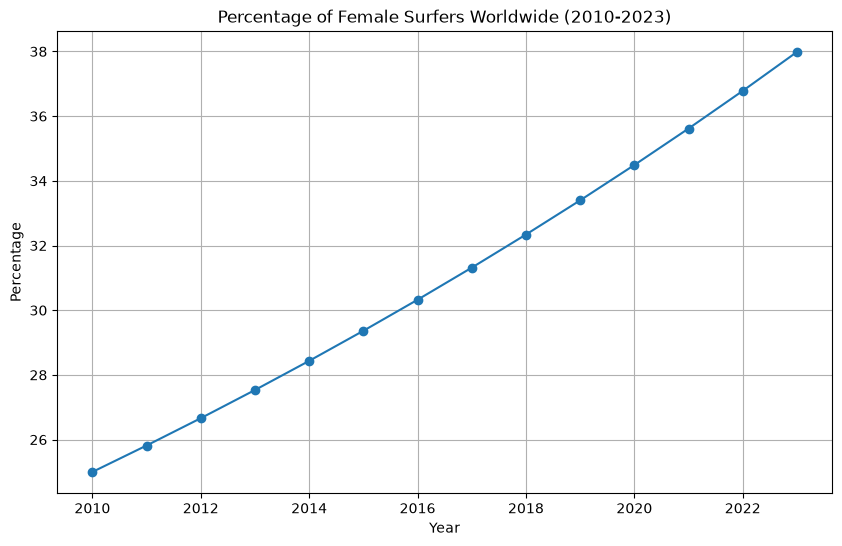

In [32]:
scraped_gender_stat = [{"label":"2010","value":25,"display":"25 Percent"},{"label":"2011","value":25.8175,"display":"25.8 Percent"},{"label":"2012","value":26.661732249999996,"display":"26.7 Percent"},{"label":"2013","value":27.533570894574993,"display":"27.5 Percent"},{"label":"2014","value":28.433918662827594,"display":"28.4 Percent"},{"label":"2015","value":29.363707803102056,"display":"29.4 Percent"},{"label":"2016","value":30.32390104826349,"display":"30.3 Percent"},{"label":"2017","value":31.315492612541707,"display":"31.3 Percent"},{"label":"2018","value":32.33950922097182,"display":"32.3 Percent"},{"label":"2019","value":33.3970111724976,"display":"33.4 Percent"},{"label":"2020","value":34.48909343783827,"display":"34.5 Percent"},{"label":"2021","value":35.616886793255574,"display":"35.6 Percent"},{"label":"2022","value":36.78155899139504,"display":"36.8 Percent"},{"label":"2023","value":37.984315970413654,"display":"38 Percent"}]

scraped_gender_stat = {
    int(item["label"]): item["value"]
    for item in scraped_gender_stat
}
print('The amount of female surfers through the years in % worldwide:\nSource: Priyanka Sharma. "Surfing Industry Statistics." Gitnux, 13 Feb 2026, https://gitnux.org/surfing-industry-statistics.')
#display(scraped_gender_stat)
#add visualisation for scraped_gender_stat
import matplotlib.pyplot as plt

years = list(scraped_gender_stat.keys())
values = list(scraped_gender_stat.values())

plt.figure(figsize=(10, 6))
plt.plot(years, values, marker='o')
plt.title('Percentage of Female Surfers Worldwide (2010-2023)')
plt.xlabel('Year')
plt.ylabel('Percentage')
plt.grid(True)
plt.show()

In [33]:
injuries_stat_per_activity_1 = pd.DataFrame(
    [
        ["Walking (Recreational)", 214006, 4.7, 348589, 5.6, 3334, 6.7, 565929, 5.2],
        ["Running/jogging", 222460, 11.6, 168030, 12.0, 584, 3.3, 391074, 11.8],
        ["Football/soccer", 159918, 19.1, 37655, 16.9, 391, 10.7, 197964, 18.6],
        ["Bush walking", 64922, 3.8, 82503, 4.2, 1278, 6.6, 148703, 4.0],
        ["Basketball", 84635, 13.2, 22113, 9.9, 472, 11.9, 107220, 12.4],
        ["Australian football", 83425, 20.7, 16827, 15.8, 599, 42.5, 100851, 19.7],
        ["Cycling", 73546, 6.5, 21131, 3.0, 887, 10.3, 95564, 5.2],
        ["Tennis", 59380, 10.0, 27477, 6.6, 560, 24.0, 87417, 8.7],
        ["Netball", 9662, 15.4, 76235, 23.8, 455, 34.3, 86352, 22.5],
        ["Golf", 68249, 8.5, 14695, 7.7, None, None, 82945, 8.3],
        ["Swimming", 31868, 2.1, 33989, 2.0, 785, 4.4, 66642, 2.1],
        ["Cricket", 53835, 13.3, 5842, 8.8, None, None, 59678, 12.7],
        ["Pilates", 2422, 2.0, 40527, 3.3, 144, 3.7, 43093, 3.2],
        ["Hockey", 17386, 36.3, 15863, 33.7, None, None, 33250, 34.9],
        ["Athletics, track and field", 21973, 13.1, 9201, 10.6, None, None, 31174, 12.2],
        ["Volleyball", 18723, 16.4, 11360, 14.0, 198, 15.3, 30281, 15.4],
        ["Yoga", 8453, 5.1, 20323, 2.2, None, None, 28776, 2.7],
        ["Crossfit/Functional fitness", 10994, 20.3, 14432, 17.4, 210, 100.0, 25636, 18.7],
        ["Weight lifting", 17060, 11.2, 8246, 7.5, 194, 8.4, 25501, 9.6],
        ["Rugby league", 20140, 18.5, 4446, 13.7, 222, 21.4, 24809, 17.4],
    ],
    columns=[
        "activity",
        "male_estimate", "male_percent",
        "female_estimate", "female_percent",
        "other_estimate", "other_percent",
        "total_estimate", "total_percent",
    ],
)
injuries_stat_per_activity_2 = pd.DataFrame(
    [
        ["Yoga", 8453, 5.1, 20323, 2.2, None, None, 28776, 2.7],
        ["Wrestling", 1243, 18.2, 166, 16.5, 185, 46.5, 1594, 19.3],
        ["Wood chopping", 274, 3.8, 234, 13.3, None, None, 508, 5.7],
        ["Weight lifting", 17060, 11.2, 8246, 7.5, 194, 8.4, 25501, 9.6],
        ["Waterskiing/Wakeboarding", 1291, 5.8, 622, 3.7, None, None, 1913, 4.9],
        ["Water polo", 1086, 11.0, 1091, 16.9, None, None, 2176, 13.3],
        ["Walking (Recreational)", 214006, 4.7, 348589, 5.6, 3334, 6.7, 565929, 5.2],
        ["Volleyball", 18723, 16.4, 11360, 14.0, 198, 15.3, 30281, 15.4],
        ["Virtual based physical activity", 2023, 2.1, 2498, 2.8, 205, 8.0, 4726, 2.6],
        ["Underwater sports", 1630, 1.8, 709, 0.8, None, None, 2339, 1.3],
        ["Triathlon", 2614, 14.8, 414, 4.3, None, None, 3028, 11.1],
        ["Touch football", 16121, 16.9, 7515, 15.2, None, None, 23636, 16.3],
        ["Tenpin bowling", 2000, 2.9, 1333, 2.2, None, None, 3333, 2.6],
        ["Tennis", 59380, 10.0, 27477, 6.6, 560, 24.0, 87417, 8.7],
        ["Taekwondo", 3726, 29.9, 1575, 18.2, None, None, 5302, 24.4],
        ["Table tennis", 4225, 1.9, 1520, 1.5, None, None, 5745, 1.8],
        ["Synchronised swimming", 362, 5.4, 385, 5.1, None, None, 748, 5.3],
        ["Sword fighting", 401, 18.9, None, None, None, None, 401, 10.1],
        ["Swimming", 31868, 2.1, 33989, 2.0, 785, 4.4, 66642, 2.1],
        ["Surfing", 16760, 9.5, 6047, 5.5, None, None, 22807, 7.9],
    ],
    columns=[
        "activity",
        "male_estimate", "male_percent",
        "female_estimate", "female_percent",
        "other_estimate", "other_percent",
        "total_estimate", "total_percent",
    ],
)

injuries_stat_per_activity = (
    pd.concat(
        [injuries_stat_per_activity_1, injuries_stat_per_activity_2],
        ignore_index=True,
    )
    .drop_duplicates(subset="activity", keep="first")
    .reset_index(drop=True)
)
print("Injuries statistics per activity.\n Source: AUSPLAY. ")
display(injuries_stat_per_activity)

Injuries statistics per activity.
 Source: AUSPLAY. 


,activity,male_estimate,male_percent,female_estimate,female_percent,other_estimate,other_percent,total_estimate,total_percent
0,Walking (Recreational),214006,4.7,348589.0,5.6,3334.0,6.7,565929,5.2
1,Running/jogging,222460,11.6,168030.0,12.0,584.0,3.3,391074,11.8
2,Football/soccer,159918,19.1,37655.0,16.9,391.0,10.7,197964,18.6
3,Bush walking,64922,3.8,82503.0,4.2,1278.0,6.6,148703,4.0
4,Basketball,84635,13.2,22113.0,9.9,472.0,11.9,107220,12.4
5,Australian football,83425,20.7,16827.0,15.8,599.0,42.5,100851,19.7
6,Cycling,73546,6.5,21131.0,3.0,887.0,10.3,95564,5.2
7,Tennis,59380,10.0,27477.0,6.6,560.0,24.0,87417,8.7
8,Netball,9662,15.4,76235.0,23.8,455.0,34.3,86352,22.5
9,Golf,68249,8.5,14695.0,7.7,NaN,NaN,82945,8.3


In [34]:
injury_percent_by_sex = injuries_stat_per_activity.melt(
    id_vars="activity",
    value_vars=["female_percent", "male_percent"],
    var_name="sex",
    value_name="injury_percent",
)
injury_percent_by_sex["sex"] = injury_percent_by_sex["sex"].map(
    {"female_percent": "F", "male_percent": "M"}
)

fig = px.bar(
    injury_percent_by_sex,
    x="activity",
    y="injury_percent",
    color="sex",
    barmode="group",
    labels={
        "activity": "Activity",
        "injury_percent": "Percentage of Injuries",
        "sex": "Sex",
    },
    title="Comparison of Injuries by Sex Across Different Sports",
)
fig.show()

In [35]:
male_sport_participation_with_age = pd.DataFrame(
    [
        [
            "Surfing",
            8339, 1.7,
            17066, 1.4,
            37414, 1.9,
            36548, 1.9,
            42061, 2.6,
            28529, None,
        ],
        [
            "Swimming",
            66680, 13.3,
            156745, 12.7,
            292264, 14.7,
            321909, 17.2,
            267191, 16.3,
            240736, None,
        ],
    ],
    columns=[
        "sport",
        "age_15_17_estimate", "age_15_17_participation_rate",
        "age_18_24_estimate", "age_18_24_participation_rate",
        "age_25_34_estimate", "age_25_34_participation_rate",
        "age_35_44_estimate", "age_35_44_participation_rate",
        "age_45_54_estimate", "age_45_54_participation_rate",
        "age_55_64_estimate", "age_55_64_participation_rate",
    ],
)
print("Here we can see male sport participation with age breakdown for Surfing and Swimming.\nSource: AUSPLAY. ")
display(male_sport_participation_with_age)


Here we can see male sport participation with age breakdown for Surfing and Swimming.
Source: AUSPLAY. 


,sport,age_15_17_estimate,age_15_17_participation_rate,age_18_24_estimate,age_18_24_participation_rate,age_25_34_estimate,age_25_34_participation_rate,age_35_44_estimate,age_35_44_participation_rate,age_45_54_estimate,age_45_54_participation_rate,age_55_64_estimate,age_55_64_participation_rate
0,Surfing,8339,1.7,17066,1.4,37414,1.9,36548,1.9,42061,2.6,28529,None
1,Swimming,66680,13.3,156745,12.7,292264,14.7,321909,17.2,267191,16.3,240736,None


In [36]:
female_sport_participation_with_age = pd.DataFrame(
    [
        [
            "Surfing",
            9780, 2.1,
            14419, 1.3,
            29829, 1.5,
            27511, 1.4,
            17983, 1.1,
            15178, None,
        ],
        [
            "Swimming",
            103859, 22.0,
            207692, 18.1,
            367771, 18.6,
            359130, 18.8,
            282145, 16.8,
            236436, None,
        ],
    ],
    columns=[
        "sport",
        "age_15_17_estimate", "age_15_17_participation_rate",
        "age_18_24_estimate", "age_18_24_participation_rate",
        "age_25_34_estimate", "age_25_34_participation_rate",
        "age_35_44_estimate", "age_35_44_participation_rate",
        "age_45_54_estimate", "age_45_54_participation_rate",
        "age_55_64_estimate", "age_55_64_participation_rate",
    ],
)

print("Female sport participation by age, for Surfing and Swimming.\nSource: AUSPLAY. ")
display(female_sport_participation_with_age)

Female sport participation by age, for Surfing and Swimming.
Source: AUSPLAY. 


,sport,age_15_17_estimate,age_15_17_participation_rate,age_18_24_estimate,age_18_24_participation_rate,age_25_34_estimate,age_25_34_participation_rate,age_35_44_estimate,age_35_44_participation_rate,age_45_54_estimate,age_45_54_participation_rate,age_55_64_estimate,age_55_64_participation_rate
0,Surfing,9780,2.1,14419,1.3,29829,1.5,27511,1.4,17983,1.1,15178,None
1,Swimming,103859,22.0,207692,18.1,367771,18.6,359130,18.8,282145,16.8,236436,None


In [37]:
age_groups = ["15 - 17", "18 - 24", "25 - 34", "35 - 44", "45 - 54", "55 - 64"]
age_column_keys = ["15_17", "18_24", "25_34", "35_44", "45_54", "55_64"]
participation_rows = []

for gender, sport_data in [
    ("M", male_sport_participation_with_age),
    ("F", female_sport_participation_with_age),
]:
    for _, sport_row in sport_data.iterrows():
        for age_group, age_key in zip(age_groups, age_column_keys):
            estimate = sport_row[f"age_{age_key}_estimate"]
            rate = sport_row[f"age_{age_key}_participation_rate"]
            participants = estimate * rate / 100 if pd.notna(estimate) and pd.notna(rate) else None
            participation_rows.append(
                {
                    "sport": sport_row["sport"],
                    "age_group": age_group,
                    "gender": gender,
                    "estimate": estimate,
                    "participation_rate": rate,
                    "participants": participants,
                }
            )

sport_participation_by_age = pd.DataFrame(participation_rows)

from IPython.display import display

for sport in ["Surfing", "Swimming"]:
    sport_data = sport_participation_by_age[
        sport_participation_by_age["sport"] == sport
    ]
    fig = px.bar(
        sport_data,
        x="age_group",
        y="participants",
        color="gender",
        barmode="group",
        category_orders={
            "age_group": age_groups,
            "gender": ["F", "M"],
        },
        hover_data={
            "estimate": ":,",
            "participation_rate": ":.1f",
            "participants": ":,.1f",
        },
        labels={
            "age_group": "Age group",
            "participants": "Estimated participants",
            "gender": "Sex",
            "estimate": "Population estimate",
            "participation_rate": "Participation rate (%)",
        },
        title=f"Estimated {sport} Participants by Age and Sex",
    )
    fig.update_layout(template="plotly_white", legend_title_text="Sex")
    fig.update_yaxes(tickformat=",.0f", rangemode="tozero")
    display(fig)